# 01. Сбор данных, очистка, EDA и статистика

**Цель проекта.** Научить модель оценивать содержание **CaO** в карбонатном сырье
(известняк, мергель, мел) по быстрому анализу примесей: SiO₂, Al₂O₃, Fe₂O₃, MgO, K₂O,
Na₂O, TiO₂, P₂O₅, MnO. На цементном производстве CaO — главный показатель сырья:
от него зависит, сколько известняка класть в смесь. Отдельное измерение CaO дорогое,
а примеси меряют и так, так что оценка по ним пригодилась бы и для контроля качества.

**Что делаем в этом ноутбуке:**
1. берём датасет, собранный скриптом `src/build_dataset.py` из открытой геохимической базы;
2. смотрим, как он очищен, и проверяем результат;
3. делаем EDA и статистические тесты. Их выводы потом используются в `02_modeling.ipynb`.

Потери при прокаливании (LOI) в признаки не берём: они почти повторяют CaO (через CO₂),
а на практике «по примесям» этого значения у нас не будет.

### Мини-словарик

| Термин | Что значит |
|---|---|
| Оксиды | Состав породы принято записывать оксидами: CaO — «известь», SiO₂ — кремнезём, MgO — магнезия. Значения в масс. %, т.е. граммов на 100 г породы |
| LOI | Потеря массы при прокаливании. У карбонатов это в основном улетевший CO₂ |
| Предел обнаружения | Меньше этой концентрации прибор вещество не видит и пишет просто «меньше предела» |
| NaN | Пустая ячейка, значение не измерили |
| EDA | Первый осмотр данных: таблицы и графики, чтобы понять, что там вообще есть |
| p-value | Результат теста. p < 0.05 — различие или связь вряд ли случайны; p большое — разницы не видно |
| Корреляция Спирмена (ρ) | От −1 до +1: насколько две величины растут и падают вместе |
| Источник (`ref_id`) | Научная статья, откуда взяты анализы. Пробы из одной статьи похожи друг на друга |

### Как устроен проект
1. Этот ноутбук: разбираемся с данными.
2. Ноутбук 02: строим модели и проверяем их на источниках, которых модель не видела.
3. Папка `app/`: готовая модель (функция, командная строка, веб-сервис).

## 0. Подготовка

Подключаем библиотеки и читаем `data/carbonates_cao.csv`. Одна строка — одна проба,
столбцы — оксиды, координаты и номер публикации.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src.features import load_data, make_groups, stoichiometric_cao, FEATURES, TARGET

warnings.filterwarnings("ignore")  # чтобы предупреждения библиотек не мешали читать вывод
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
FIG = "reports/figures/"  # сюда сохраняются картинки для отчёта
df = load_data()
print(df.shape)
df.head()

(3208, 19)


,sample_id,rock_class,rock_name,latitude,longitude,ref_id,country_id,sio2,al2o3,fe2o3_tot,mgo,k2o,na2o,tio2,p2o5,mno,loi,cao,n_censored
0,2725,limestone,limestone,33.320400,132.376718,17152,102,6.80,1.06,0.580000,1.22,0.27,0.05,0.045,0.068,0.200,NaN,49.50,0
1,5993,calcareous_other,a-type fine grained homogeneousx greyish black...,38.784443,141.419447,16225,102,22.72,8.10,6.610918,1.84,0.58,0.65,0.230,12.510,0.820,NaN,30.64,0
2,6795,marl,marl,-6.625190,106.885110,6582,91,14.99,5.61,4.940000,8.63,0.34,0.55,0.210,0.140,1.640,32.97,28.71,0
3,14584,limestone,limestone,52.571700,-161.205500,12406,210,10.40,3.51,1.177978,2.09,0.78,0.39,0.150,0.133,5.445,35.67,40.38,0
4,45797,limestone,limestone,39.980810,16.187640,11957,98,9.98,0.60,3.200000,1.30,0.31,0.39,0.040,0.220,0.570,35.55,47.85,0


## 1. Источник данных и очистка

Источник — *Global whole-rock geochemical database compilation* (Gard et al., 2019,
Zenodo, DOI 10.5281/zenodo.2592822): около миллиона анализов горных пород из публикаций.
Скрипт `build_dataset.py` делает вот что:

| Шаг | Что делает |
|---|---|
| Отбор | Только осадочные породы, по названию — известняк, мергель, мел, «карбонат», «известковистая». Доломиты, песчаники, граувакки и т.п. выкинуты |
| Пределы обнаружения | В базе значение «ниже предела» записано как `-предел`. Заменяем на `|x|/2` (так принято в геохимии) и считаем, сколько таких значений в пробе (`n_censored`). Нули считаем пропусками |
| Железо | Приводим к одной форме Fe₂O₃ (из `fe2o3_tot`, `feo_tot` или `fe2o3 + 1.1113·FeO`) |
| Границы | CaO от 5 до 56.1 % (56.1 % — чистый CaCO₃), сумма оксидов не больше 105 % |
| Дубликаты | Одинаковые по составу и координатам пробы удалены |

Порог CaO ≥ 5 % появился не сразу. После первого прохода среди проб с подписью
«chalk» и «carbonate» нашлись образцы с CaO ≈ 0. Это ошибки разметки: «меловой»
там по возрасту, а не по составу.

Посмотрим, сколько проб каждого класса и из скольких публикаций они пришли. Если
какого-то класса или источника слишком много, это повлияет на то, как проверять модель.

In [2]:
print("Классы пород:")
print(df["rock_class"].value_counts().to_string())
print(f"\nИсточников (публикаций): {df['ref_id'].nunique()}")
top = df["ref_id"].value_counts().head(5)  # пять самых крупных публикаций
print("Крупнейшие источники (доля проб):")
print((top / len(df)).round(3).to_string())

Классы пород:
rock_class
limestone           1961
calcareous_other    1218
marl                  25
chalk                  4

Источников (публикаций): 88
Крупнейшие источники (доля проб):
ref_id
18088    0.541
34       0.092
33       0.046
14795    0.036
15912    0.029


**Вывод.** Мергелей всего 25, мела 4, остальное — известняки и «карбонатные» породы.
Поэтому учим модель на всём карбонатном сырье, а по мергелю и мелу смотрим результат
только как на проверку переноса, не как на основную метрику. И ещё: одна публикация
даёт больше половины проб. Это риск утечки при обычной кросс-валидации (см. раздел 5).

## 2. Пропуски

Считаем, какую долю значений по каждому оксиду не измерили. Модели не любят пустые
ячейки, так что надо решить, чем их заполнять и можно ли самому факту пропуска доверять.

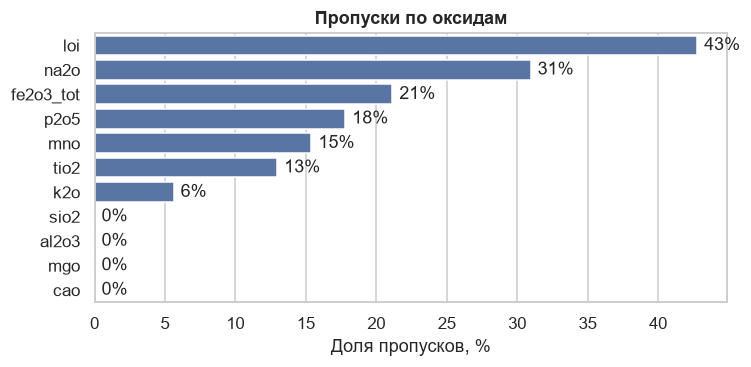

Доля проб с цензурированными значениями: 0.012


In [3]:
# доля пустых ячеек по столбцам, в процентах
miss = df[FEATURES + [TARGET, "loi"]].isna().mean().sort_values(ascending=False) * 100
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=miss.values, y=miss.index, color="#4C72B0", ax=ax)
ax.set(xlabel="Доля пропусков, %", ylabel="", title="Пропуски по оксидам")
for i, v in enumerate(miss.values):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center")
plt.tight_layout(); plt.savefig(FIG + "missing.png"); plt.show()
print("Доля проб с цензурированными значениями:", (df["n_censored"] > 0).mean().round(3))

**Вывод.** Больше всего пропусков у Na₂O (31 %), Fe₂O₃ (21 %) и P₂O₅ (18 %); у LOI
43 %, но он нам не нужен. Пропуски не случайны, они зависят от публикации и метода
анализа. Отсюда три решения: (а) импутация только внутри пайплайна, чтобы не было
утечки; (б) полезен признак `n_missing`; (в) деревья, которые сами понимают NaN
(LightGBM, CatBoost), — естественные кандидаты.

## 3. Распределения и выбросы

Гистограммы показывают форму распределений и выбросы. От этого зависит, какие тесты
и модели подходят.

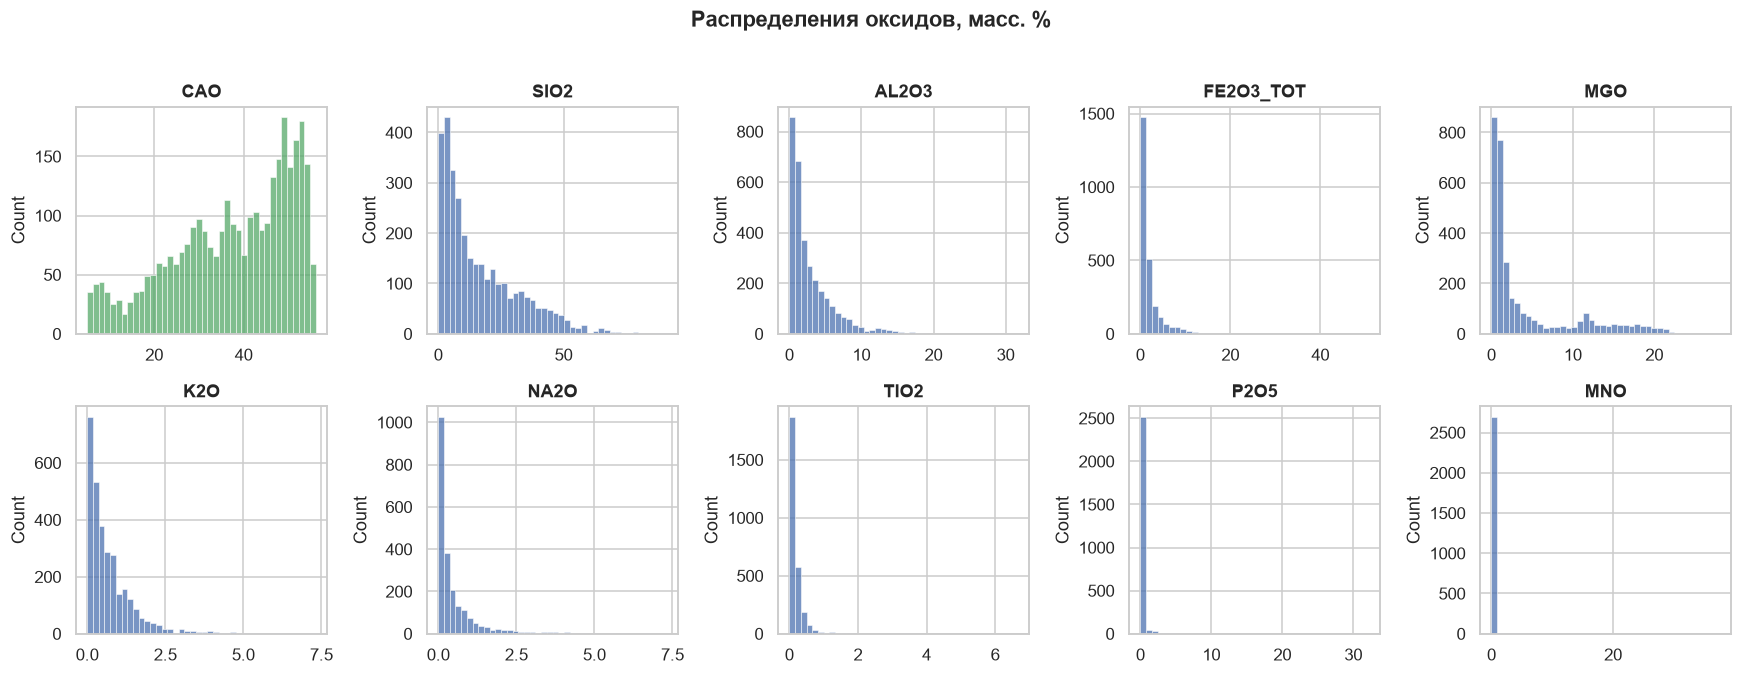

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.ravel(), [TARGET] + FEATURES):  # CaO зелёным, признаки синим
    sns.histplot(df[col].dropna(), bins=40, ax=ax, color="#55A868" if col == TARGET else "#4C72B0")
    ax.set_title(col.upper())
    ax.set_xlabel("")
plt.suptitle("Распределения оксидов, масс. %", y=1.02, fontweight="bold")
plt.tight_layout(); plt.savefig(FIG + "distributions.png", bbox_inches="tight"); plt.show()

In [5]:
# count, среднее, медиана, 99-й перцентиль, максимум; skew > 0 = длинный хвост вправо
desc = df[[TARGET] + FEATURES].describe(percentiles=[.5, .99]).T[["count", "mean", "50%", "99%", "max"]]
desc["skew"] = df[[TARGET] + FEATURES].skew()
desc.round(2)

,count,mean,50%,99%,max,skew
cao,3208.0,37.25,39.50,55.18,56.10,-0.59
sio2,3208.0,16.71,11.10,64.19,91.19,1.18
al2o3,3208.0,2.91,1.70,14.69,31.70,2.11
fe2o3_tot,2530.0,2.04,1.04,12.90,50.79,6.50
mgo,3208.0,4.51,1.40,21.20,28.06,1.51
k2o,3028.0,0.71,0.47,3.79,7.32,2.38
na2o,2215.0,0.53,0.21,4.33,7.32,3.51
tio2,2792.0,0.17,0.09,1.30,6.66,8.35
p2o5,2637.0,0.44,0.08,9.30,32.20,9.99
mno,2714.0,0.14,0.06,0.91,37.59,43.44


**Вывод.** CaO бимодален: пик на 50–55 % (чистые известняки) и широкий «хвост» на
10–40 % (мергели, глинистые и доломитизированные породы). Малые оксиды (K₂O, Na₂O,
TiO₂, P₂O₅, MnO) сильно скошены вправо. Для линейных моделей это повод брать
логарифмические отношения и робастные оценки, деревьям преобразования не нужны.

### Проверка нормальности (Шапиро–Уилка)

Проверяем, похожи ли распределения на «колокол». От этого зависит выбор тестов:
Пирсону и ANOVA нужна нормальность, непараметрическим критериям — нет.

In [6]:
rows = []
for col in [TARGET] + FEATURES:
    # тест Шапиро–Уилка рассчитан примерно на 5000 значений, поэтому берём случайные 5000
    x = df[col].dropna().sample(min(5000, df[col].notna().sum()), random_state=0)
    w, p = stats.shapiro(x)  # p < 0.05 значит «не нормальное»
    rows.append({"оксид": col, "W": round(w, 3), "p": p, "normal (p>0.05)": p > 0.05})
shap_res = pd.DataFrame(rows)
print(shap_res.to_string(index=False))

    оксид     W            p  normal (p>0.05)
      cao 0.934 1.612379e-35            False
     sio2 0.874 3.688731e-45            False
    al2o3 0.778 1.208388e-54            False
fe2o3_tot 0.525 1.258518e-63            False
      mgo 0.721 1.097509e-58            False
      k2o 0.774 7.860105e-54            False
     na2o 0.592 4.746334e-58            False
     tio2 0.501 1.106080e-66            False
     p2o5 0.128 1.569624e-76            False
      mno 0.073 1.684690e-78            False


**Вывод.** Ни один оксид не распределён нормально (p < 0.05). Поэтому дальше
используем **непараметрические** критерии (Спирмен, Краскел–Уоллис, Манна–Уитни),
а не Пирсона и ANOVA.

## 4. Связь оксидов с CaO

Считаем корреляцию Спирмена каждого оксида с CaO: какие оксиды «двигаются» вместе
с ним и насколько сильно. Спирмен, а не Пирсон — из-за ненормальности (см. выше).

In [7]:
sp = []
for col in FEATURES:
    sub = df[[col, TARGET]].dropna()  # только пробы, где известны оба значения
    rho, p = stats.spearmanr(sub[col], sub[TARGET])
    sp.append({"оксид": col, "n": len(sub), "rho": rho, "p-value": p})
sp = pd.DataFrame(sp).sort_values("rho")
print(sp.round(4).to_string(index=False))

    оксид    n     rho  p-value
     sio2 3208 -0.7758      0.0
fe2o3_tot 2530 -0.6793      0.0
     tio2 2792 -0.6781      0.0
    al2o3 3208 -0.6478      0.0
      k2o 3028 -0.5987      0.0
      mgo 3208 -0.5898      0.0
     na2o 2215 -0.3439      0.0
      mno 2714 -0.2684      0.0
     p2o5 2637 -0.2625      0.0


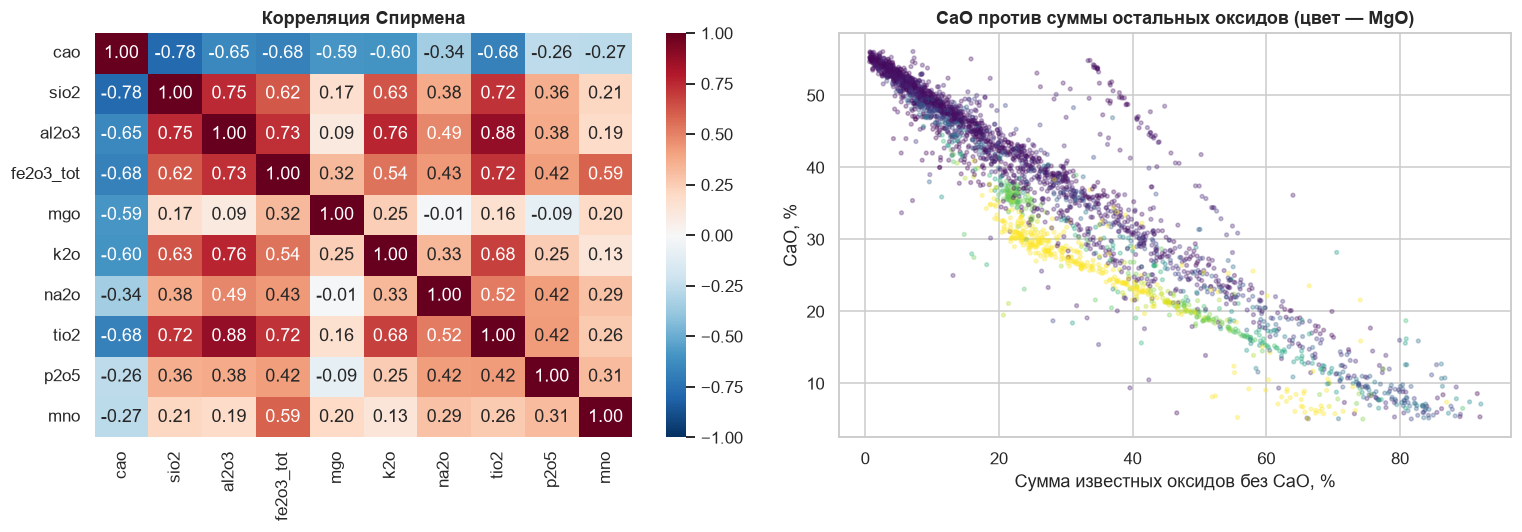

Спирмен CaO ~ сумма оксидов: rho=-0.935, p=0.0e+00


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
corr = df[[TARGET] + FEATURES].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Корреляция Спирмена")
# сумма всех оксидов-примесей в пробе, пропуски считаем нулями
df["oxide_sum"] = df[FEATURES].fillna(0).sum(axis=1)
axes[1].scatter(df["oxide_sum"], df[TARGET], s=6, alpha=.3, c=df["mgo"].clip(upper=15), cmap="viridis")
axes[1].set(xlabel="Сумма известных оксидов без CaO, %", ylabel="CaO, %",
            title="CaO против суммы остальных оксидов (цвет — MgO)")
plt.tight_layout(); plt.savefig(FIG + "correlations.png", bbox_inches="tight"); plt.show()
rho_sum, p_sum = stats.spearmanr(df["oxide_sum"], df[TARGET])
print(f"Спирмен CaO ~ сумма оксидов: rho={rho_sum:.3f}, p={p_sum:.1e}")

**Вывод.** CaO отрицательно связан со всеми примесями, сильнее всего с SiO₂
(ρ = −0.78), затем идут Fe₂O₃, TiO₂ и Al₂O₃ (около −0.65…−0.68): глина и кремнезём
«разбавляют» карбонат. С суммой остальных оксидов корреляция ρ = −0.94. Это закон
сохранения массы: анализ в сумме даёт 100 %, и то, что не заняли примеси, достаётся
CaO и CO₂ (потерям при прокаливании). Что из этого следует для моделирования:
1. добавляем признаки `oxide_sum` и `stoich_cao` (баланс масс);
2. формула баланса масс — серьёзный конкурент для ML, и обыграть её надо честно.

### Мультиколлинеарность (VIF)

Проверяем, не дублируют ли признаки друг друга. Если два признака почти одинаковы,
линейная модель становится неустойчивой. Тревожный сигнал — VIF выше 5–10.

In [9]:
# VIF не считается с пропусками, поэтому временно заполняем медианой
vif_df = df[FEATURES].fillna(df[FEATURES].median())
vif = pd.Series([variance_inflation_factor(vif_df.values, i) for i in range(vif_df.shape[1])],
                index=FEATURES).sort_values(ascending=False)
print(vif.round(2).to_string())

al2o3        3.33
tio2         1.93
sio2         1.84
k2o          1.81
na2o         1.49
fe2o3_tot    1.39
mgo          1.09
p2o5         1.01
mno          1.01


**Вывод.** VIF у всех признаков невысокий (максимум 3.3 у Al₂O₃). Сильной
мультиколлинеарности нет, линейная модель устойчива и без отбора признаков.

## 5. Различия между классами пород и источниками

Сначала проверим, отличаются ли классы пород по CaO. Если да, метка породы полезна как
признак. Если нет, опираться на неё не стоит.

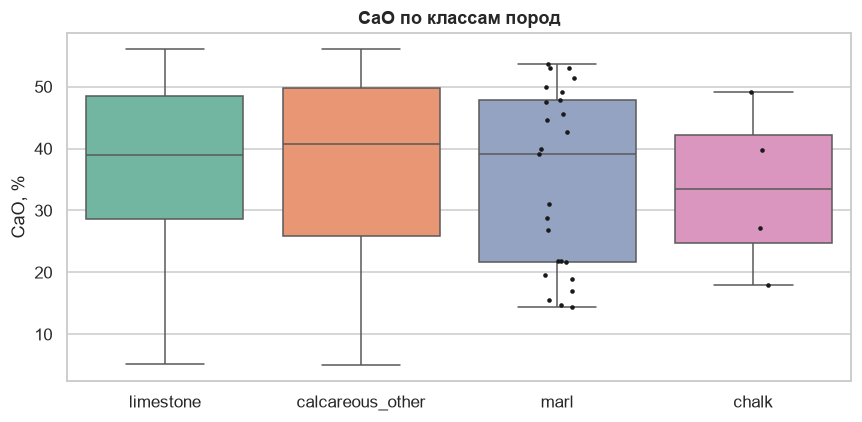

Краскел–Уоллис по классам: H=1.4, p=7.12e-01
Манн–Уитни limestone vs marl: U=27222, p=0.342; медианы 39.0 vs 39.1


In [10]:
order = ["limestone", "calcareous_other", "marl", "chalk"]
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=df, x="rock_class", y=TARGET, order=order, ax=ax, palette="Set2")
sns.stripplot(data=df[df.rock_class.isin(["marl", "chalk"])], x="rock_class", y=TARGET,
              order=order, color="k", size=3, ax=ax)
ax.set(xlabel="", ylabel="CaO, %", title="CaO по классам пород")
plt.tight_layout(); plt.savefig(FIG + "cao_by_class.png"); plt.show()

# Краскел–Уоллис — аналог ANOVA без требования нормальности: все ли классы из одного распределения?
groups_cao = [g[TARGET].values for _, g in df.groupby("rock_class")]
h, p_kw = stats.kruskal(*groups_cao)
print(f"Краскел–Уоллис по классам: H={h:.1f}, p={p_kw:.2e}")
lime, marl = df[df.rock_class == "limestone"][TARGET], df[df.rock_class == "marl"][TARGET]
# Манн–Уитни — то же, но для двух групп
u, p_u = stats.mannwhitneyu(lime, marl)
print(f"Манн–Уитни limestone vs marl: U={u:.0f}, p={p_u:.3f}; медианы {lime.median():.1f} vs {marl.median():.1f}")

**Вывод.** Классы пород по CaO статистически **не различаются** (Краскел–Уоллис
p = 0.71, «известняк – мергель» p = 0.34, медианы 39.0 и 39.1 %), а у мела всего 4
пробы. Подпись породы в базе ненадёжна: «мергели» из разных публикаций имеют разный
состав. К тому же у новой пробы на производстве такой метки нет. Поэтому в модель
метку **не берём**, только используем в анализе ошибок. Состав определяется химией, а
не названием.

Теперь то же самое для источников. Если пробы одной публикации похожи друг на друга, то
обычное случайное разбиение на train и test завысит качество: модель просто «узнает»
знакомый источник.

Краскел–Уоллис CaO между 6 крупнейшими источниками: H=408.2, p=5.02e-86


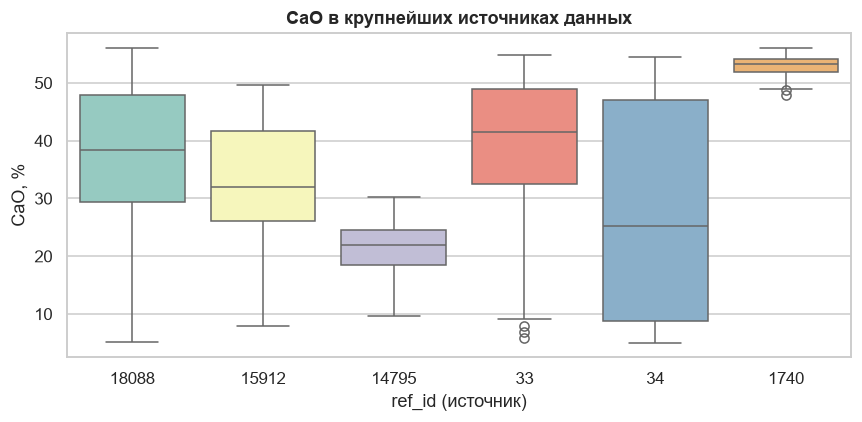

In [11]:
df["group"] = make_groups(df)  # группы для валидации: источник, а самый большой ещё и по блокам
big_ref = df["ref_id"].value_counts().idxmax()
top_refs = df["ref_id"].value_counts().head(6).index  # шесть самых крупных источников
sub = df[df.ref_id.isin(top_refs)]
h_ref, p_ref = stats.kruskal(*[g[TARGET].values for _, g in sub.groupby("ref_id")])
print(f"Краскел–Уоллис CaO между 6 крупнейшими источниками: H={h_ref:.1f}, p={p_ref:.2e}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=sub, x=sub.ref_id.astype(str), y=TARGET, ax=ax, palette="Set3")
ax.set(xlabel="ref_id (источник)", ylabel="CaO, %", title="CaO в крупнейших источниках данных")
plt.tight_layout(); plt.savefig(FIG + "cao_by_source.png"); plt.show()

**Вывод.** CaO сильно различается между публикациями (p ≪ 0.05): у каждой свои
месторождения, лаборатория и метод. Пробы одного источника похожи друг на друга
сильнее, чем на чужие, и обычная случайная кросс-валидация даст завышенный результат
(утечка через источник). **Решение:** `GroupKFold` по источнику, а крупнейшую публикацию
(54 % проб) дополнительно режем на 8 географических блоков (`make_groups`).

## 6. География

Наносим пробы на карту, цвет — CaO. Хочется понять, откуда данные. Если почти всё из
одной страны, нельзя обещать такое же качество в других регионах.

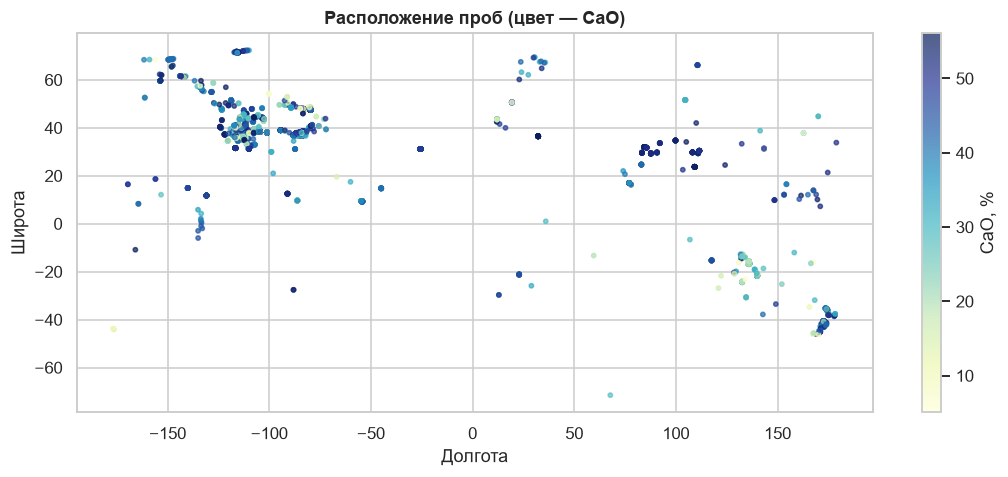

Доля проб из США (country_id=210): 0.55


In [12]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sc = ax.scatter(df["longitude"], df["latitude"], c=df[TARGET], s=8, cmap="YlGnBu", alpha=.7)
plt.colorbar(sc, label="CaO, %")
ax.set(xlabel="Долгота", ylabel="Широта", title="Расположение проб (цвет — CaO)")
plt.tight_layout(); plt.savefig(FIG + "map.png"); plt.show()
print("Доля проб из США (country_id=210):", round((df.country_id == 210).mean(), 2))

**Вывод.** Данные в основном из США (55 % проб, и большая часть — одна публикация),
значит, в других регионах качество, скорее всего, будет ниже. Это честно отражаем в
ограничениях решения.

## 7. Проверка физического признака

Прежде чем строить baseline на балансе масс, убедимся, что он правда работает.
Сравним ошибки формулы для чистых известняков (CaO > 45 %) и для глинистых
(CaO < 30 %).

MAE стехиометрии: чистые 1.43 vs глинистые/доломитовые 2.57, Манн–Уитни p=1.1e-45
Общий R² стехиометрии: 0.926


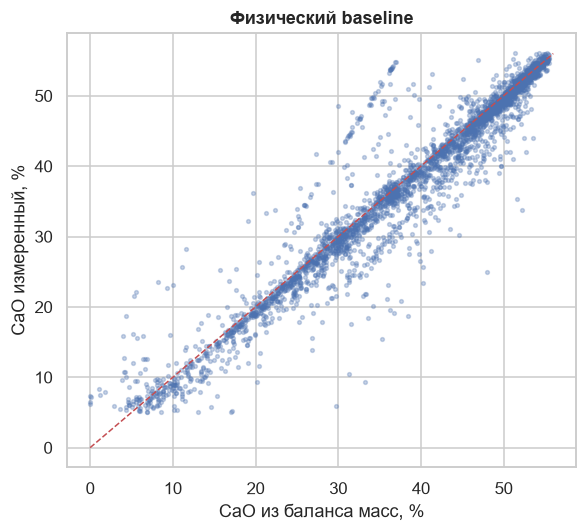

In [13]:
# оценка CaO по формуле из src/features.py, без обучения
df["stoich"] = stoichiometric_cao(df[FEATURES])
df["abs_err_stoich"] = (df["stoich"] - df[TARGET]).abs()
hi, lo = df[df[TARGET] > 45]["abs_err_stoich"], df[df[TARGET] < 30]["abs_err_stoich"]
u, p = stats.mannwhitneyu(hi, lo)
print(f"MAE стехиометрии: чистые {hi.mean():.2f} vs глинистые/доломитовые {lo.mean():.2f}, Манн–Уитни p={p:.1e}")
print("Общий R² стехиометрии:", round(np.corrcoef(df["stoich"], df[TARGET])[0, 1] ** 2, 3))

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(df["stoich"], df[TARGET], s=6, alpha=.3)
ax.plot([0, 56], [0, 56], "r--", lw=1)  # красная линия — идеальное совпадение
ax.set(xlabel="CaO из баланса масс, %", ylabel="CaO измеренный, %", title="Физический baseline")
plt.tight_layout(); plt.savefig(FIG + "stoich.png"); plt.show()

**Вывод.** Формула баланса масс уже объясняет около 92 % дисперсии CaO, но у глинистых
и доломитовых пород ошибка заметно больше: там CO₂ связан не только с кальцитом,
есть ещё вода, сульфаты, органика. Здесь у ML и есть шанс что-то улучшить: поправить
формулу в «сложных» составах. Но выигрыш стоит ждать скромный, в проценты RMSE, а не в разы.

## Итоги ноутбука

* Собран и очищен датасет из 3208 карбонатных проб (88 источников, 9 признаков и CaO).
* Пропуски неслучайны → импутация только внутри пайплайна и нативные NaN в бустингах.
* Распределения не нормальны → непараметрические тесты.
* CaO определяется балансом масс (ρ ≈ −0.9 с суммой остальных оксидов) → добавляем
  признаки `oxide_sum`, `stoich_cao`, `log_si_al`, `mg_share`, `n_missing`, а саму
  формулу берём как сильный физический baseline.
* Источники сильно различаются → только групповая валидация (`GroupKFold`).
* Метка породы CaO статистически не различает (p = 0.71) и на производстве её нет → не используем.

Дальше: `02_modeling.ipynb`.